# Flight delays: a data playbook for corporate travel

**One notebook, one source of truth.** Every number and chart in the slides comes from this notebook.

**How to read it.** Each section starts with a **Question**, then the **code** that answers it (with comments on what each step does and why), then a plain-words **Answer**. Cells marked **Slide** feed a slide.

### The data rules (important)

| What we do | Data we use | Why |
|---|---|---|
| Basic statistics (how often, when, how much) | **All 6.4 million flights** | No sampling error. These are facts, not estimates. |
| Train the model | **The 200,000-flight sample** | Fast to train, and it is the data every team received. |
| Test the model | **All other flights (about 6.2 million)** | Flights the model never saw, so the score is honest. |

### Questions we answer

| # | Question | Slide |
|---|---|---|
| 1 | Is the sample a fair copy of all flights? | |
| 2 | How often are flights disrupted? | 2 |
| 3 | Does departure time matter? | 2, 6 |
| 4 | How late is "late"? | 3 |
| 5 | Does the month (or carrier, weekday) matter? | 9 |
| 6 | What does a delay cost? | 5 |
| 7 | Can a model predict late flights? Is accuracy the right score? | 4 |
| 8 | Does the risk score rank flights well? | 7 |
| 9 | Which model should we use? | Appendix |
| 10 | What drives the risk? | 9 |
| 11 | What if we change the hour or month? | 9 |
| 12 | Where should the cutoff be? | 8 |
| 13 | Does a Low / Medium / High badge work? | 7 |
| 14 | What does "book before 10 am" save? | 6 |
| 15 | What is the business case? | 10 |
| 16 | Every number used in the slides | all |

## 0. Setup

* **Imports**: the tools we use (pandas for tables, matplotlib for charts).
* **Paths**: change `DATA` to the folder that holds both data folders.
* **Assumptions**: numbers that are *not* in any dataset. Change them and re-run the whole notebook to see how the dollars move.

In [1]:
import warnings, json
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- where the data lives (change this one line) ----
DATA = Path('data')
SAMPLE_CSV = DATA / 'student_sample_200k' / 'questrom_flights_2025_student.csv'   # 200,000 flights
FULL_DIR = DATA / 'full_2025'                                              # all 6.4 million flights, 12 monthly files

# ---- ASSUMPTIONS (change these, then re-run) ----
VALUE_OF_TIME = 60        # $ per hour of a traveler's time
CANCEL_HOURS = 4          # hours lost when a flight is cancelled
ACTION_MIN = 15           # minutes spent acting on a flagged flight (add a buffer, switch flights)
PROGRAM_FLIGHTS = 2000    # flights a company books per year (illustrative size)
AVG_FARE = 235.49         # average fare, DOT Consumer Airfare Report 2025, Table 1a, passenger-weighted

# ---- chart style (same colors as the slides) ----
GREEN, ORANGE, NAVY, GRAY, LIGHT = '#1F7A55', '#C8501E', '#0F3D2E', '#6B7670', '#9CB9AA'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#E3ECE6', 'axes.axisbelow': True,
                     'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

R = {}   # results: every number used in the slides is stored here (shown in section 16)

## 1. Load the data

> **Question 1: Is the 200,000-flight sample a fair copy of all 6.4 million flights?**

We need to know, because we will train on the sample and describe the world with the full data. Each flight has a unique key (date, carrier, flight number, airports, scheduled time), so we can also tell exactly **which full-data flights are in the sample**. Those must stay out of the test set.

In [2]:
sample = pd.read_csv(SAMPLE_CSV, low_memory=False)

KEYS = ['FL_DATE', 'OP_UNIQUE_CARRIER', 'OP_CARRIER_FL_NUM', 'ORIGIN', 'DEST', 'CRS_DEP_TIME']   # identifies one flight
COLS = KEYS + ['MONTH', 'DAY_OF_WEEK', 'OP_CARRIER', 'DISTANCE', 'ARR_DELAY', 'CANCELLED', 'DIVERTED']
full = pd.concat([pd.read_csv(f, usecols=COLS, low_memory=False) for f in sorted(FULL_DIR.glob('2025_*.csv'))],
                 ignore_index=True)                                 # glue the 12 months together

def add_flags(d):
    d['hour'] = (d['CRS_DEP_TIME'] // 100).clip(0, 23)                                    # scheduled departure hour
    d['flew'] = (d['CANCELLED'] != 1) & (d['DIVERTED'] != 1) & d['ARR_DELAY'].notna()    # the flight actually arrived
    d['late'] = d['ARR_DELAY'] >= 15                                                      # late = 15+ minutes after schedule
    d['disrupted'] = (d['CANCELLED'] == 1) | (d['DIVERTED'] == 1) | d['late']            # cancelled, diverted or late
    return d
sample, full = add_flags(sample), add_flags(full)

# mark which full-data flights are in the sample (they must not be used for testing)
sample_keys = sample[KEYS].drop_duplicates().assign(in_sample=True)
full = full.merge(sample_keys, on=KEYS, how='left')
full['in_sample'] = full['in_sample'].fillna(False).astype(bool)

print(f'Full data: {len(full):,} flights | Sample: {len(sample):,} flights | sample flights found inside full data: {full.in_sample.sum():,}')

Full data: 6,398,056 flights | Sample: 200,000 flights | sample flights found inside full data: 200,000


In [3]:
# Compare the sample with all flights on the headline numbers
def headline(d):
    return pd.Series({'flights': len(d),
                      'disrupted %': d['disrupted'].mean() * 100,
                      'cancelled %': (d['CANCELLED'] == 1).mean() * 100,
                      'late % (of flights that flew)': d.loc[d.flew, 'late'].mean() * 100,
                      'late % at 6 am': d.loc[d.flew & (d.hour == 6), 'late'].mean() * 100,
                      'late % at 7 pm': d.loc[d.flew & (d.hour == 19), 'late'].mean() * 100})
compare = pd.DataFrame({'all flights': headline(full), '200k sample': headline(sample)}).round(2)
compare['difference'] = (compare['200k sample'] - compare['all flights']).round(2)
R['n_full'], R['n_sample'] = len(full), len(sample)
compare

,all flights,200k sample,difference
flights,6398056.00,200000.00,-6198056.00
disrupted %,23.55,23.49,-0.06
cancelled %,1.49,1.45,-0.04
late % (of flights that flew),22.17,22.14,-0.03
late % at 6 am,9.83,9.66,-0.17
late % at 7 pm,32.66,33.69,1.03


**Answer 1: Yes.** The sample matches all flights within a fraction of a point on every headline number (disrupted 23.49% vs 23.55%). All 200,000 sample flights were found inside the full data, so we can remove them and test the model on the rest: **6,088,351 flights it has never seen**. The tiny gaps (for example 33.7% vs 32.7% late at 7 pm) are why every plain statistic in this notebook uses all flights.

## 2. How big is the problem?

> **Question 2: How often are flights disrupted?**

* **Disrupted** = cancelled, diverted, or arrived 15+ minutes late.
* **Late** = arrived 15+ minutes after schedule (the standard BTS "delay 15" rule).
* Late rate is measured on flights that actually flew.

**Slide 2** uses the three donuts.

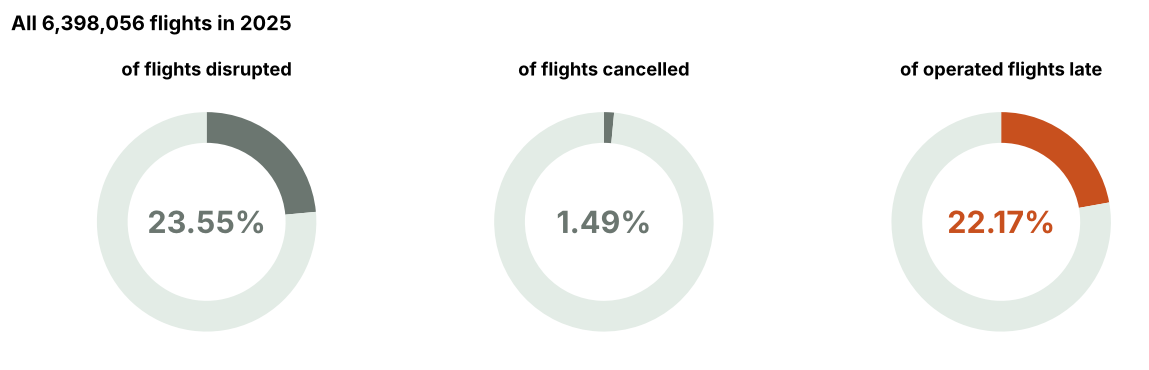

1,506,548 flights were disrupted in 2025


In [4]:
# SLIDE 2: the three headline percentages, all flights
R['disrupted_pct'] = full['disrupted'].mean() * 100
R['cancelled_pct'] = (full['CANCELLED'] == 1).mean() * 100
R['late_pct'] = full.loc[full.flew, 'late'].mean() * 100
R['disrupted_n'] = int(full['disrupted'].sum())
R['n_flew'] = int(full['flew'].sum())

def donut(ax, pct, title, color):
    ax.pie([pct, 100 - pct], colors=[color, '#E3ECE6'], startangle=90, counterclock=False, wedgeprops={'width': 0.28})
    ax.text(0, 0, f'{pct:.2f}%', ha='center', va='center', fontsize=20, fontweight='bold', color=color)
    ax.set_title(title, loc='center', fontsize=12)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
donut(axes[0], R['disrupted_pct'], 'of flights disrupted', GRAY)
donut(axes[1], R['cancelled_pct'], 'of flights cancelled', GRAY)
donut(axes[2], R['late_pct'], 'of operated flights late', ORANGE)
plt.suptitle(f"All {len(full):,} flights in 2025", x=0.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()
print(f"{R['disrupted_n']:,} flights were disrupted in 2025")

**Answer 2: about 1 in 4.** **23.55%** of 2025 flights were disrupted (1,506,548 flights). Cancellations are only 1.49%; the rest is lateness (22.17% of flights that flew). Lateness is the problem to solve.

## 3. When you fly

> **Question 3: Does departure time matter?**

We group flights by **scheduled departure hour** and look at the share that arrive late. Then we compare two simple bands: **before 10 am** and **5 pm or later**.

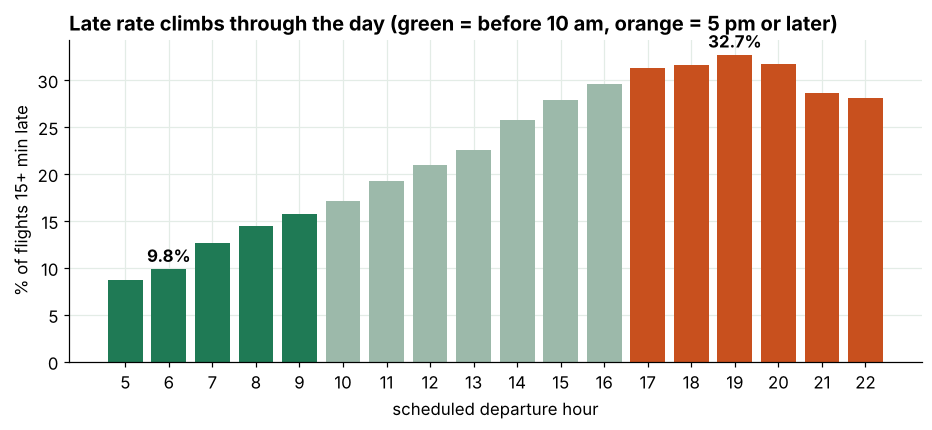

In [5]:
# SLIDE 2: late rate by scheduled departure hour (all flights that flew)
late_by_hour = full[full.flew].groupby('hour')['late'].mean() * 100
R['late_6am'], R['late_7pm'] = late_by_hour[6], late_by_hour[19]

shown = late_by_hour.loc[5:22]
colors = [GREEN if h < 10 else (ORANGE if h >= 17 else LIGHT) for h in shown.index]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(shown.index, shown.values, color=colors)
for h in (6, 19):
    ax.text(h, shown[h] + 0.8, f'{shown[h]:.1f}%', ha='center', fontweight='bold')
ax.set_xticks(range(5, 23)); ax.set_xlabel('scheduled departure hour'); ax.set_ylabel('% of flights 15+ min late')
ax.set_title('Late rate climbs through the day (green = before 10 am, orange = 5 pm or later)')
plt.show()

In [6]:
# SLIDES 2 and 6: before 10 am vs 5 pm or later
early = full.flew & (full.hour < 10)
evening = full.flew & (full.hour >= 17)
R['late_before10'] = full.loc[early, 'late'].mean() * 100
R['late_after17'] = full.loc[evening, 'late'].mean() * 100
R['n_before10'], R['n_after17'] = int(early.sum()), int(evening.sum())
R['ratio_evening_morning'] = R['late_after17'] / R['late_before10']

# how sure are we? a 95% interval for a share is p +/- 1.96 x sqrt(p(1-p)/n)
def ci95(p, n): return 1.96 * np.sqrt(p * (1 - p) / n) * 100
print(f"Before 10 am : {R['late_before10']:.2f}% late  (+/- {ci95(R['late_before10']/100, R['n_before10']):.2f}) on {R['n_before10']:,} flights")
print(f"5 pm or later: {R['late_after17']:.2f}% late  (+/- {ci95(R['late_after17']/100, R['n_after17']):.2f}) on {R['n_after17']:,} flights")
print(f"Evening is {R['ratio_evening_morning']:.1f}x the morning late rate")

Before 10 am : 12.66% late  (+/- 0.05) on 1,880,182 flights
5 pm or later: 30.80% late  (+/- 0.07) on 1,778,460 flights
Evening is 2.4x the morning late rate


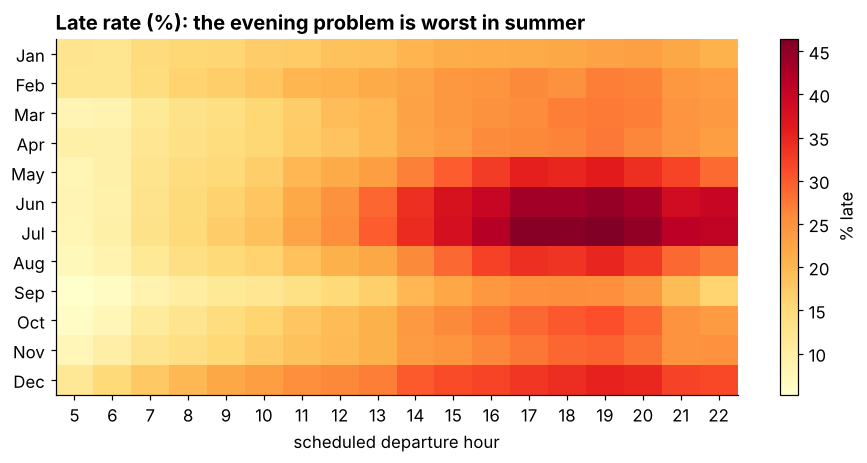

Worst hour-month cell: 46.4% late; best: 5.3% late


In [7]:
# EXTRA: does the hour effect change by month? (late rate, hour x month, all flights)
grid = full[full.flew & full.hour.between(5, 22)].pivot_table(index='MONTH', columns='hour', values='late', aggfunc='mean') * 100
fig, ax = plt.subplots(figsize=(10, 4.2))
im = ax.imshow(grid.values, cmap='YlOrRd', aspect='auto')
ax.set_xticks(range(len(grid.columns))); ax.set_xticklabels(grid.columns); ax.set_yticks(range(12)); ax.set_yticklabels(MONTHS)
ax.set_xlabel('scheduled departure hour'); ax.set_title('Late rate (%): the evening problem is worst in summer')
ax.grid(False); plt.colorbar(im, label='% late'); plt.show()
R['late_worst_cell'] = float(np.nanmax(grid.values))
print(f"Worst hour-month cell: {R['late_worst_cell']:.1f}% late; best: {np.nanmin(grid.values):.1f}% late")

In [8]:
# SLIDE 4: the danger zone vs the calm zone (all flights that flew)
d = full[full.flew]
hot = d.MONTH.isin([6, 7]) & d.hour.between(17, 20)          # June-July, 5 pm to 8:59 pm departures
calm = (d.MONTH == 9) & (d.hour < 10)                        # September, before 10 am
R['hot_late'], R['hot_n'] = d.loc[hot, 'late'].mean() * 100, int(hot.sum())
R['calm_late'], R['calm_n'] = d.loc[calm, 'late'].mean() * 100, int(calm.sum())
R['hot_ratio'] = R['hot_late'] / R['calm_late']
print(f"June-July, 5-8 pm departures: {R['hot_late']:.1f}% late ({R['hot_n']:,} flights)")
print(f"September, before 10 am     : {R['calm_late']:.1f}% late ({R['calm_n']:,} flights)")
print(f"Danger zone is {R['hot_ratio']:.1f}x the calm zone")

June-July, 5-8 pm departures: 44.6% late (246,593 flights)
September, before 10 am     : 8.8% late (153,342 flights)
Danger zone is 5.1x the calm zone


**Answer 3: yes, a lot.** Flights leaving before 10 am are late **12.7%** of the time; from 5 pm, **30.8%** (**2.4x**). The gap is far wider than the margin of error (about 0.05 points). The heatmap adds that the evening problem is worst in June and July (up to 46% late) and mild in September. The sharpest contrast: June-July departures between 5 and 8 pm are late **44.6%** of the time (246,593 flights) vs **8.8%** for September before 10 am (**5.1x**).

## 4. How late is "late"?

> **Question 4: Are late flights a little late or a lot late?**

We split arrival delay into **five severity groups** (cutoffs at 15, 60, 120 and 180 minutes). This tells us how big a **buffer** a traveler needs.

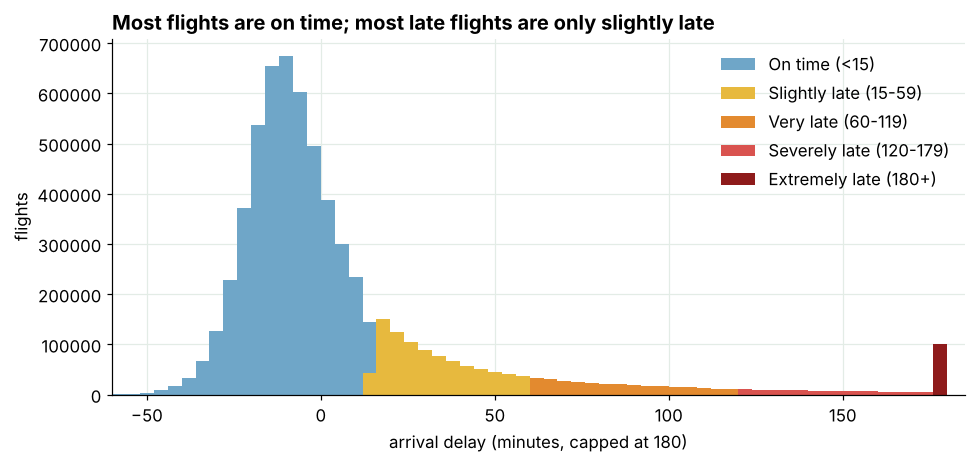

ARR_DELAY
On time (<15)              77.8
Slightly late (15-59)      14.1
Very late (60-119)          4.8
Severely late (120-179)     1.7
Extremely late (180+)       1.6
Arrive within 60 minutes of schedule: 91.9%   |   Late flights under an hour late: 63.6%


In [9]:
# SLIDE 3: arrival delay of every flight that flew, colored by severity group
d = full.loc[full.flew, 'ARR_DELAY']
groups = pd.cut(d, bins=[-np.inf, 15, 60, 120, 180, np.inf], right=False,
                labels=['On time (<15)', 'Slightly late (15-59)', 'Very late (60-119)', 'Severely late (120-179)', 'Extremely late (180+)'])
shares = groups.value_counts(normalize=True).sort_index() * 100
R['sev_shares'] = shares.round(2).tolist()
R['within60_pct'] = (d < 60).mean() * 100                          # arrive within an hour of schedule
R['late_under60_of_late'] = ((d >= 15) & (d < 60)).sum() / (d >= 15).sum() * 100

colors5 = ['#6FA6C8', '#E7B93E', '#E38A2F', '#D9534F', '#8E1B1B']
fig, ax = plt.subplots(figsize=(10, 4.2))
bins = np.linspace(-60, 180, 61)
for (lo, hi), lab, col in zip([(-1e9, 15), (15, 60), (60, 120), (120, 180), (180, 1e9)], shares.index, colors5):
    ax.hist(d[(d >= lo) & (d < hi)].clip(upper=180), bins=bins, color=col, label=lab)
ax.set_xlim(-60, 185); ax.set_xlabel('arrival delay (minutes, capped at 180)'); ax.set_ylabel('flights')
ax.legend(frameon=False); ax.set_title('Most flights are on time; most late flights are only slightly late'); plt.show()
print(shares.round(1).to_string())
print(f"Arrive within 60 minutes of schedule: {R['within60_pct']:.1f}%   |   Late flights under an hour late: {R['late_under60_of_late']:.1f}%")

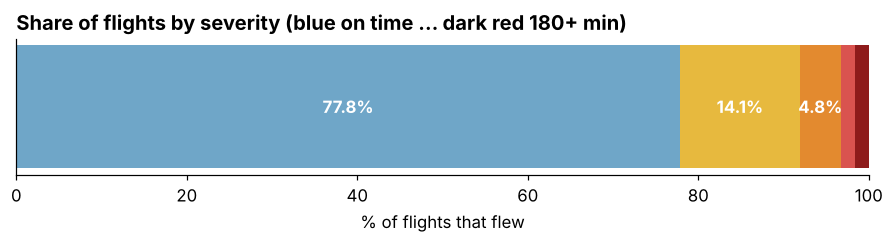

In [10]:
# EXTRA: the same five groups as one bar, to see the shares at a glance
fig, ax = plt.subplots(figsize=(10, 1.6))
left = 0
for share, lab, col in zip(shares.values, shares.index, colors5):
    ax.barh(0, share, left=left, color=col)
    if share > 3: ax.text(left + share / 2, 0, f'{share:.1f}%', ha='center', va='center', color='white', fontweight='bold')
    left += share
ax.set_xlim(0, 100); ax.set_yticks([]); ax.set_xlabel('% of flights that flew'); ax.grid(False)
ax.set_title('Share of flights by severity (blue on time ... dark red 180+ min)'); plt.show()

**Answer 4: mostly slightly late.** 91.9% of flights arrive within an hour of schedule, and 63.6% of late flights are under an hour late. So a **one-hour buffer** covers most cases, and a real plan B is needed for only about 8% of flights.

## 5. Season, weekday and carrier

> **Question 5: Does the month matter? What about weekday and carrier?**

Before modelling, a quick look at the other clues. Month is measured on **disruption** (cancellations are very seasonal), weekday and carrier on the **late rate**.

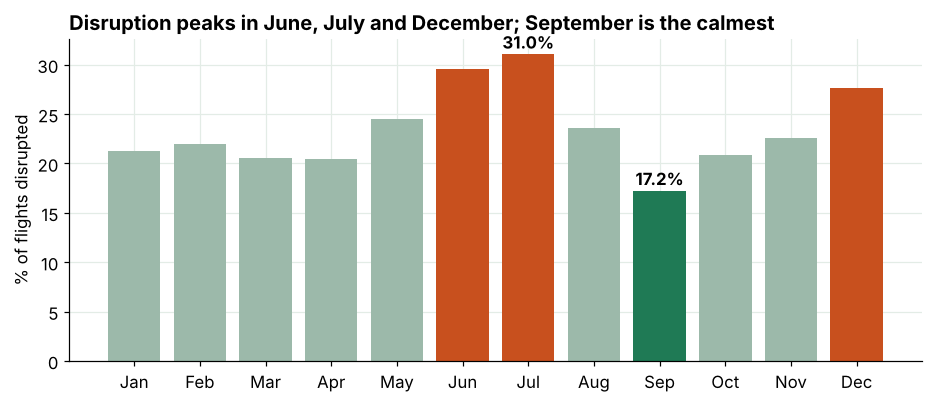

In [11]:
# SLIDE 9: disruption rate by month, all flights
by_month = full.groupby('MONTH')['disrupted'].mean() * 100
R['dis_by_month'] = by_month.round(2).to_dict()
cols = [ORANGE if m in (6, 7, 12) else (GREEN if m == 9 else LIGHT) for m in by_month.index]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(range(12), by_month.values, color=cols)
for i in (6, 8): ax.text(i, by_month.values[i] + 0.6, f'{by_month.values[i]:.1f}%', ha='center', fontweight='bold')
ax.set_xticks(range(12)); ax.set_xticklabels(MONTHS); ax.set_ylabel('% of flights disrupted')
ax.set_title('Disruption peaks in June, July and December; September is the calmest'); plt.show()

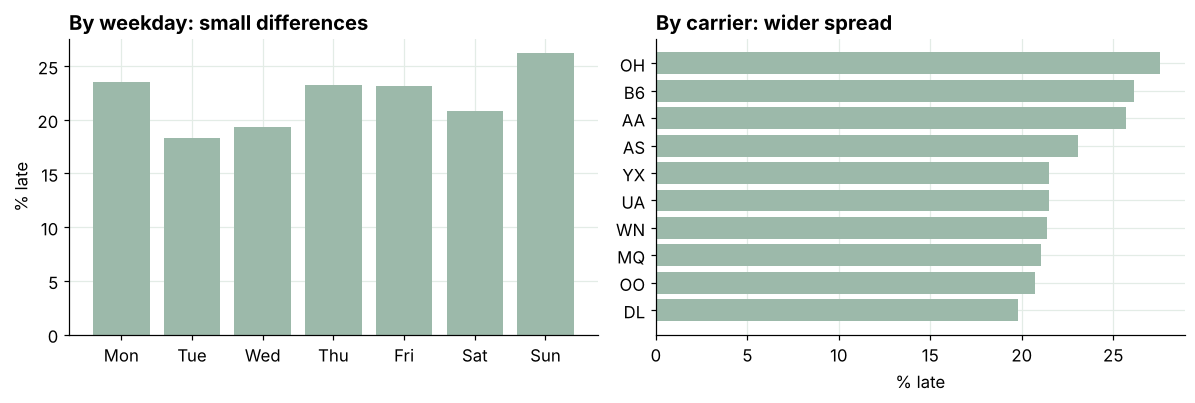

Weekday range: 18.3% to 26.2%   |   Carrier range: 19.8% to 27.5%


In [12]:
# EXTRA: weekday and carrier (late rate among flights that flew)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
wk = full[full.flew].groupby('DAY_OF_WEEK')['late'].mean() * 100
axes[0].bar(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], wk.values, color=LIGHT)
axes[0].set_ylabel('% late'); axes[0].set_title('By weekday: small differences')
car = (full[full.flew].groupby('OP_CARRIER')['late'].mean() * 100).sort_values()
axes[1].barh(car.index, car.values, color=LIGHT); axes[1].set_xlabel('% late'); axes[1].set_title('By carrier: wider spread')
plt.tight_layout(); plt.show()
print(f"Weekday range: {wk.min():.1f}% to {wk.max():.1f}%   |   Carrier range: {car.min():.1f}% to {car.max():.1f}%")

**Answer 5: month matters most.** Disruption runs from 17.2% in September to 31.0% in July (June 29.6%, December 27.6%). Weekday (18% to 26% late) and carrier (20% to 28%) also move the late rate by several points, so the model uses them as extra clues. Rule: buy flexible fares for June, July and December.

## 6. What does a delay cost?

> **Question 6: How many dollars is a delay worth to a traveler?**

**Expected cost = chance it happens x how long it lasts x what an hour is worth.** Two inputs are assumptions (`VALUE_OF_TIME`, `CANCEL_HOURS`, set at the top). Everything else is counted from all flights.

First, the fare context from the **DOT Consumer Airfare Report 2025 (Table 1a)**: what a ticket costs, so we can say what share of the fare a delay adds.

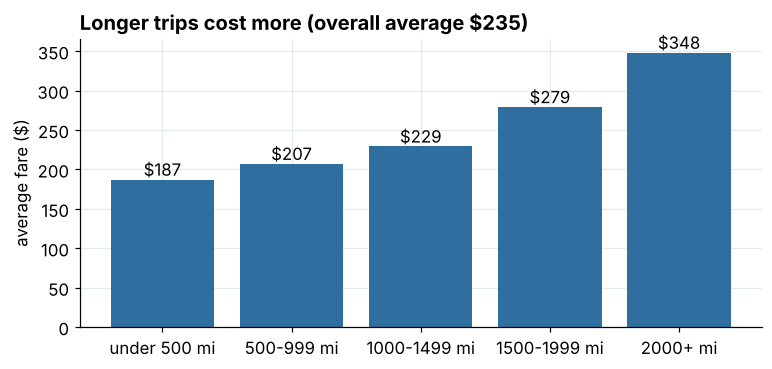

In [13]:
# Average fare by trip length (DOT Consumer Airfare Report 2025, Table 1a, passenger-weighted; values saved from the report)
fares = pd.DataFrame({'distance band': ['under 500 mi', '500-999 mi', '1000-1499 mi', '1500-1999 mi', '2000+ mi'],
                      'average fare ($)': [187, 207, 229, 279, 348]})
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(fares['distance band'], fares['average fare ($)'], color='#2F6F9F')
for i, v in enumerate(fares['average fare ($)']): ax.text(i, v + 5, f'${v}', ha='center')
ax.set_ylabel('average fare ($)'); ax.set_title(f'Longer trips cost more (overall average ${AVG_FARE:.0f})'); plt.show()

In [14]:
# Expected delay cost per flight, all flights
cap = full['ARR_DELAY'].clip(upper=180)                                  # cap very long delays at 180 minutes
R['late_hours'] = cap[full.flew & full.late].mean() / 60                  # average hours late, when late
share_late_all = full['late'].mean()                                       # share of ALL flights that are late
share_cancel = (full['CANCELLED'] == 1).mean()

late_cost = share_late_all * R['late_hours'] * VALUE_OF_TIME               # dollars per flight from lateness
cancel_cost = share_cancel * CANCEL_HOURS * VALUE_OF_TIME                  # dollars per flight from cancellations
R['late_cost'], R['cancel_cost'] = late_cost, cancel_cost
R['trip_cost'] = late_cost + cancel_cost
R['trip_cost_pct_fare'] = R['trip_cost'] / AVG_FARE * 100
R['miss_cost'] = R['late_hours'] * VALUE_OF_TIME                           # cost of one late flight we did nothing about
R['action_cost'] = ACTION_MIN / 60 * VALUE_OF_TIME                         # cost of acting on one flagged flight
R['break_even'] = R['action_cost'] / R['miss_cost']                        # flag a flight when its risk is above this

print(f"Late: {share_late_all:.1%} of flights, {R['late_hours']:.2f} hours late on average when late  -> ${late_cost:.2f} per flight")
print(f"Cancelled: {share_cancel:.2%} of flights, {CANCEL_HOURS} hours lost                       -> ${cancel_cost:.2f} per flight")
print(f"Expected delay cost: ${R['trip_cost']:.2f} per flight = {R['trip_cost_pct_fare']:.1f}% of the ${AVG_FARE:.0f} average fare")
print(f"One late flight costs ${R['miss_cost']:.2f}; acting on a flagged flight costs ${R['action_cost']:.2f}; break-even risk = {R['break_even']:.1%}")

Late: 21.8% of flights, 1.03 hours late on average when late  -> $13.49 per flight
Cancelled: 1.49% of flights, 4 hours lost                       -> $3.57 per flight
Expected delay cost: $17.06 per flight = 7.2% of the $235 average fare
One late flight costs $61.93; acting on a flagged flight costs $15.00; break-even risk = 24.2%


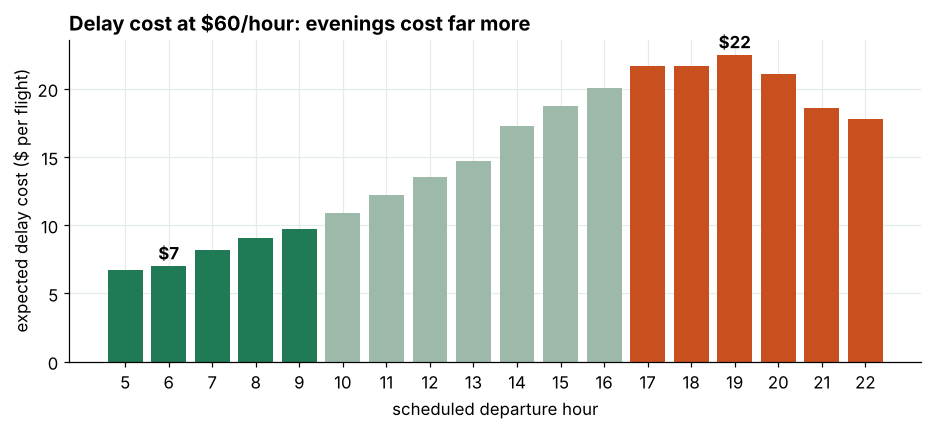

6-9 am: $8.43    5-8 pm: $21.75    ratio 2.6x


In [15]:
# SLIDE 5: expected lateness cost by departure hour (on-time counts as 0 minutes late)
late_dollars = cap.clip(lower=0) / 60 * VALUE_OF_TIME
cost_by_hour = late_dollars[full.flew].groupby(full.loc[full.flew, 'hour']).mean().loc[5:22]
band = lambda mask: late_dollars[full.flew & mask].mean()
R['cost_6_9'], R['cost_17_20'] = band(full.hour.between(6, 9)), band(full.hour.between(17, 20))
R['cost_before10'], R['cost_after17'] = band(full.hour < 10), band(full.hour >= 17)

colors = [GREEN if h < 10 else (ORANGE if h >= 17 else LIGHT) for h in cost_by_hour.index]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(cost_by_hour.index, cost_by_hour.values, color=colors)
for h in (6, 19): ax.text(h, cost_by_hour[h] + 0.5, f'${cost_by_hour[h]:.0f}', ha='center', fontweight='bold')
ax.set_xticks(range(5, 23)); ax.set_xlabel('scheduled departure hour'); ax.set_ylabel('expected delay cost ($ per flight)')
ax.set_title(f'Delay cost at ${VALUE_OF_TIME}/hour: evenings cost far more'); plt.show()
print(f"6-9 am: ${R['cost_6_9']:.2f}    5-8 pm: ${R['cost_17_20']:.2f}    ratio {R['cost_17_20'] / R['cost_6_9']:.1f}x")

In [16]:
# SLIDE 5: what if an hour of time is worth more or less? (the table behind the sensitivity)
rows = []
for vot in [30, 60, 100, 150]:
    cost = share_late_all * R['late_hours'] * vot + share_cancel * CANCEL_HOURS * vot
    rows.append({'value of time ($/h)': vot, 'cost per flight ($)': round(cost, 2),
                 '% of fare': round(cost / AVG_FARE * 100, 1), f'per year, {PROGRAM_FLIGHTS:,} flights ($)': round(cost * PROGRAM_FLIGHTS)})
vot_table = pd.DataFrame(rows)
R['vot_table'] = rows
vot_table

,value of time ($/h),cost per flight ($),% of fare,"per year, 2,000 flights ($)"
0,30,8.53,3.6,17057
1,60,17.06,7.2,34114
2,100,28.43,12.1,56856
3,150,42.64,18.1,85284


**Answer 6: about $17 of expected delay cost per flight** ($13.49 from lateness + $3.57 from cancellations), which is 7.2% of the $235 average fare. Evenings (5-8 pm) cost $21.75 against $8.43 in the morning (2.6x). At $30 to $150 an hour the cost per flight ranges from $8.53 to $42.64. One late flight costs about $62 on average, which sets the action threshold later.

## 7. The model

> **Question 7: Can a model predict which flights will be late? And is accuracy the right way to score it?**

**The setup (this is the honest way to test a model):**

* **Train** on the 200,000-flight **sample**.
* **Test** on **every other flight** (the full data minus the sample, about 6.2 million flights). The model has never seen them.
* **Clues** (features): departure hour, month, weekday, carrier, distance.
* **Target**: late (15+ minutes) or not.

The model is a **logistic regression**: it adds up a weight for each clue and turns the total into a chance of being late.

In [17]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

FEATURES = ['hour', 'MONTH', 'DAY_OF_WEEK', 'OP_CARRIER', 'DISTANCE']
train = sample[sample.flew]                                   # training data = the sample
test = full[full.flew & ~full.in_sample]                      # test data = all other flights (never seen)
X_train, y_train = train[FEATURES], train['late'].astype(int)
X_test, y_test = test[FEATURES], test['late'].astype(int)
R['n_train'], R['n_test'] = len(train), len(test)
print(f"Train: {len(train):,} flights   Test: {len(test):,} flights   Late rate: train {y_train.mean():.2%}, test {y_test.mean():.2%}")

# preprocessing: turn categories into 0/1 columns, put numbers on one scale
preprocess = ColumnTransformer([
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), ['OP_CARRIER', 'MONTH', 'DAY_OF_WEEK']),
    ('num', StandardScaler(), ['DISTANCE', 'hour'])])

model = make_pipeline(preprocess, LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)                                   # learn the weights from the sample
p_test = model.predict_proba(X_test)[:, 1]                    # chance of late for every test flight
print('Model trained. Example risk scores for the first 5 test flights:', p_test[:5].round(3))

Train: 196,523 flights   Test: 6,088,351 flights   Late rate: train 22.14%, test 22.17%


Model trained. Example risk scores for the first 5 test flights: [0.106 0.132 0.133 0.128 0.152]


Always say 'on time': accuracy 77.8%
Our model at 50%   : accuracy 77.8%   |   caught 9,646 of 1,349,855 late flights = 0.71%


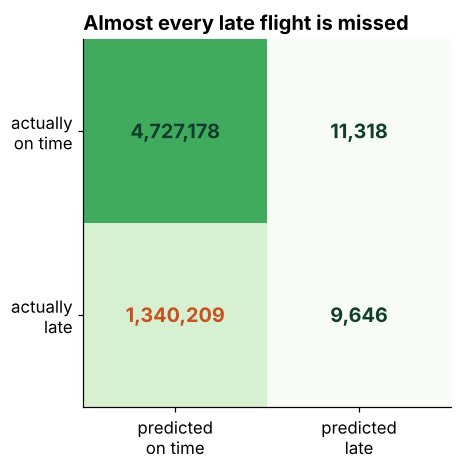

In [18]:
# SLIDE 4: a model that never warns vs our model, at the default 50% cutoff
baseline_accuracy = 1 - y_test.mean()                          # always say "on time"
pred50 = (p_test >= 0.5).astype(int)
tp = int(((pred50 == 1) & (y_test == 1)).sum()); fp = int(((pred50 == 1) & (y_test == 0)).sum())
fn = int(((pred50 == 0) & (y_test == 1)).sum()); tn = int(((pred50 == 0) & (y_test == 0)).sum())
R.update(baseline_accuracy=baseline_accuracy * 100, model_accuracy=(tp + tn) / len(y_test) * 100,
         recall50=tp / (tp + fn) * 100, flagged50=tp + fp, late_total=tp + fn, caught50=tp, tn=tn, fp=fp, fn=fn)
print(f"Always say 'on time': accuracy {R['baseline_accuracy']:.1f}%")
print(f"Our model at 50%   : accuracy {R['model_accuracy']:.1f}%   |   caught {tp:,} of {tp + fn:,} late flights = {R['recall50']:.2f}%")

fig, ax = plt.subplots(figsize=(5.2, 4.4))
cm = np.array([[tn, fp], [fn, tp]])
ax.imshow(cm, cmap='Greens', vmax=cm.max() * 1.6); ax.grid(False)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f'{v:,}', ha='center', va='center', fontsize=13, fontweight='bold', color=ORANGE if (i, j) == (1, 0) else NAVY)
ax.set_xticks([0, 1]); ax.set_xticklabels(['predicted\non time', 'predicted\nlate']); ax.set_yticks([0, 1]); ax.set_yticklabels(['actually\non time', 'actually\nlate'])
ax.set_title('Almost every late flight is missed'); plt.tight_layout(); plt.show()

**Answer 7: the model works, but accuracy hides it.** A "never warns" rule scores **77.8%** accuracy. Our model scores **77.8%** at the default 50% cutoff, the same, because it almost never says "late" (it caught 9,646 of 1,349,855 late flights, **0.7%**). Accuracy is the wrong score when one outcome is 78% of the data. The next sections judge the model on ranking and dollars instead.

## 8. Does the risk score rank flights well?

> **Question 8: Even if the 50% cutoff fails, are higher scores really riskier?**

Sort all test flights by risk score and cut them into **10 equal groups (deciles)**. If the score works, the late rate should climb from the lowest group to the highest. (The **AUC** at the end is the one-number summary: the chance a late flight gets a higher score than an on-time flight. 0.5 is a coin flip, 1.0 is perfect.)

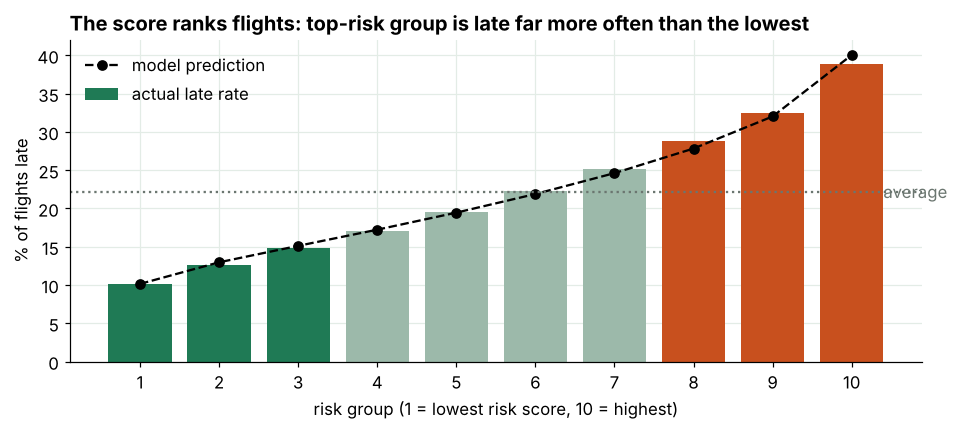

Lowest group: 10.1% late   |   Highest group: 38.9% late   |   AUC = 0.645


In [19]:
# SLIDE 7 (supporting): late rate by risk decile on the unseen test flights
from sklearn.metrics import roc_auc_score, roc_curve
R['auc'] = roc_auc_score(y_test, p_test)

dec = pd.qcut(p_test, 10, labels=False)
by_dec = pd.DataFrame({'predicted': p_test, 'actual': y_test.values, 'decile': dec}).groupby('decile').mean() * 100
R['decile_actual'] = by_dec['actual'].round(2).tolist(); R['decile_predicted'] = by_dec['predicted'].round(2).tolist()

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(range(1, 11), by_dec['actual'], color=[GREEN] * 3 + [LIGHT] * 4 + [ORANGE] * 3, label='actual late rate')
ax.plot(range(1, 11), by_dec['predicted'], 'ko--', label='model prediction')
ax.axhline(y_test.mean() * 100, color=GRAY, ls=':'); ax.text(10.4, y_test.mean() * 100, 'average', va='center', color=GRAY)
ax.set_xticks(range(1, 11)); ax.set_xlabel('risk group (1 = lowest risk score, 10 = highest)'); ax.set_ylabel('% of flights late')
ax.set_title('The score ranks flights: top-risk group is late far more often than the lowest'); ax.legend(frameon=False); plt.show()
print(f"Lowest group: {by_dec['actual'].iloc[0]:.1f}% late   |   Highest group: {by_dec['actual'].iloc[-1]:.1f}% late   |   AUC = {R['auc']:.3f}")

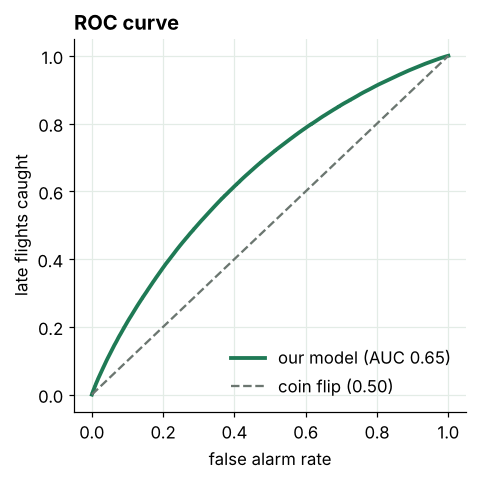

In [20]:
# EXTRA (technical): the ROC curve behind the AUC
fpr, tpr, _ = roc_curve(y_test, p_test)
fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.plot(fpr, tpr, color=GREEN, lw=2.5, label=f"our model (AUC {R['auc']:.2f})"); ax.plot([0, 1], [0, 1], color=GRAY, ls='--', label='coin flip (0.50)')
ax.set_xlabel('false alarm rate'); ax.set_ylabel('late flights caught'); ax.set_title('ROC curve'); ax.legend(frameon=False, loc='lower right'); plt.show()

**Answer 8: yes, the ranking is strong.** On unseen flights the lowest-risk tenth is late **10.1%** of the time and the highest-risk tenth **38.9%** (about 3.9x), and predictions track actual rates. AUC is 0.65: modest as a single-flight predictor, but enough to sort flights into useful risk groups.

## 9. Which model?

> **Question 9: Is a fancier model worth it?**

We compare four models by **cross-validation on the sample** (split the sample in 3 parts, train on 2, score on 1, rotate), then check each on a **500,000-flight slice of the unseen test flights**. We also show the classic **overfitting** picture: a very deep decision tree memorizes the training data and does worse on new flights.

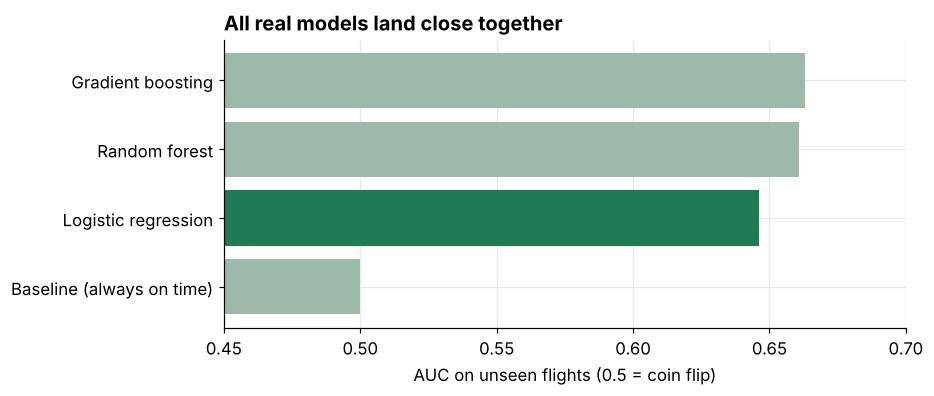

,model,AUC in sample (3-fold CV),AUC on unseen flights
0,Baseline (always on time),0.500,0.500
1,Logistic regression,0.646,0.646
2,Random forest,0.662,0.661
3,Gradient boosting,0.664,0.663


In [21]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier

test500 = test.sample(500_000, random_state=0)                 # a slice of the unseen test flights (keeps this section fast)
X500, y500 = test500[FEATURES], test500['late'].astype(int)
dense = lambda: ColumnTransformer([('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), ['OP_CARRIER', 'MONTH', 'DAY_OF_WEEK']),
                                   ('num', StandardScaler(), ['DISTANCE', 'hour'])])
models = {'Baseline (always on time)': DummyClassifier(strategy='prior'),
          'Logistic regression': LogisticRegression(max_iter=1000),
          'Random forest': RandomForestClassifier(n_estimators=60, max_depth=10, n_jobs=-1, random_state=0),
          'Gradient boosting': HistGradientBoostingClassifier(max_depth=3, random_state=0)}
rows = []
for name, est in models.items():
    pipe = make_pipeline(dense(), est)
    cv = cross_val_score(pipe, X_train, y_train, cv=3, scoring='roc_auc')       # trained and scored inside the sample
    pipe.fit(X_train, y_train)
    unseen = roc_auc_score(y500, pipe.predict_proba(X500)[:, 1])                  # scored on flights never seen
    rows.append({'model': name, 'AUC in sample (3-fold CV)': round(cv.mean(), 3), 'AUC on unseen flights': round(unseen, 3)})
compare_models = pd.DataFrame(rows)
R['models'] = rows

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(compare_models['model'], compare_models['AUC on unseen flights'], color=[LIGHT, GREEN, LIGHT, LIGHT])
ax.set_xlim(0.45, 0.7); ax.set_xlabel('AUC on unseen flights (0.5 = coin flip)'); ax.set_title('All real models land close together'); plt.show()
compare_models

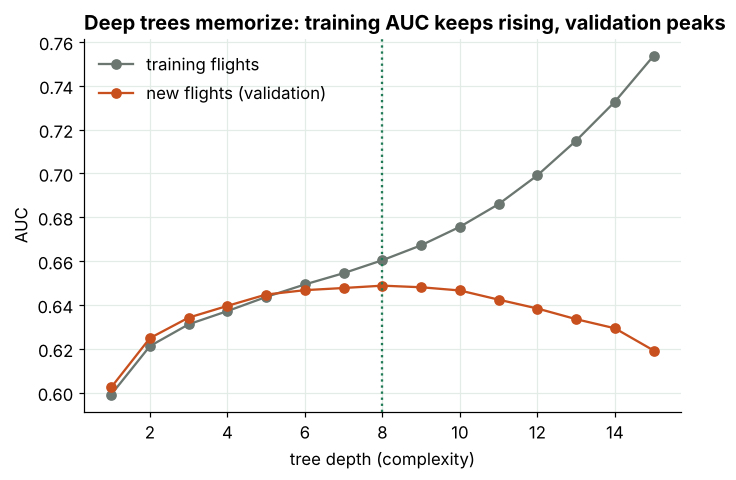

Best depth 8 (validation AUC 0.649); at depth 15 training AUC 0.75 but validation 0.62


In [22]:
# APPENDIX slide: overfitting. A deeper tree fits the training flights better and the new flights worse.
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
Xa, Xb, ya, yb = train_test_split(X_train, y_train, test_size=0.25, random_state=0, stratify=y_train)
prep = dense().fit(Xa)
tr, va = [], []
depths = range(1, 16)
for k in depths:
    tree = DecisionTreeClassifier(max_depth=k, random_state=0).fit(prep.transform(Xa), ya)
    tr.append(roc_auc_score(ya, tree.predict_proba(prep.transform(Xa))[:, 1]))
    va.append(roc_auc_score(yb, tree.predict_proba(prep.transform(Xb))[:, 1]))
R['tree_train_max'], R['tree_val_at_max_depth'], R['tree_best_depth'], R['tree_val_best'] = max(tr), va[-1], int(np.argmax(va)) + 1, max(va)

fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(depths, tr, 'o-', color=GRAY, label='training flights'); ax.plot(depths, va, 'o-', color=ORANGE, label='new flights (validation)')
ax.axvline(R['tree_best_depth'], color=GREEN, ls=':'); ax.set_xlabel('tree depth (complexity)'); ax.set_ylabel('AUC')
ax.set_title('Deep trees memorize: training AUC keeps rising, validation peaks'); ax.legend(frameon=False); plt.show()
print(f"Best depth {R['tree_best_depth']} (validation AUC {R['tree_val_best']:.3f}); at depth 15 training AUC {tr[-1]:.2f} but validation {va[-1]:.2f}")

**Answer 9: keep the simple model.** On unseen flights: logistic regression AUC 0.646, random forest 0.661, gradient boosting 0.663. The fancy models add about 0.02, not worth losing the plain-English weights. The tree-depth chart shows why more complexity backfires: training AUC reaches 0.75 at depth 15 while validation falls to 0.62 (best depth 8).

## 10. What drives the risk?

> **Question 10: Which clues push the risk up or down?**

Two views: the model's **weights** (what each clue adds, compared with a reference category), and **permutation importance** (shuffle one clue and see how much the score drops; a bigger drop means the model leans on it more).

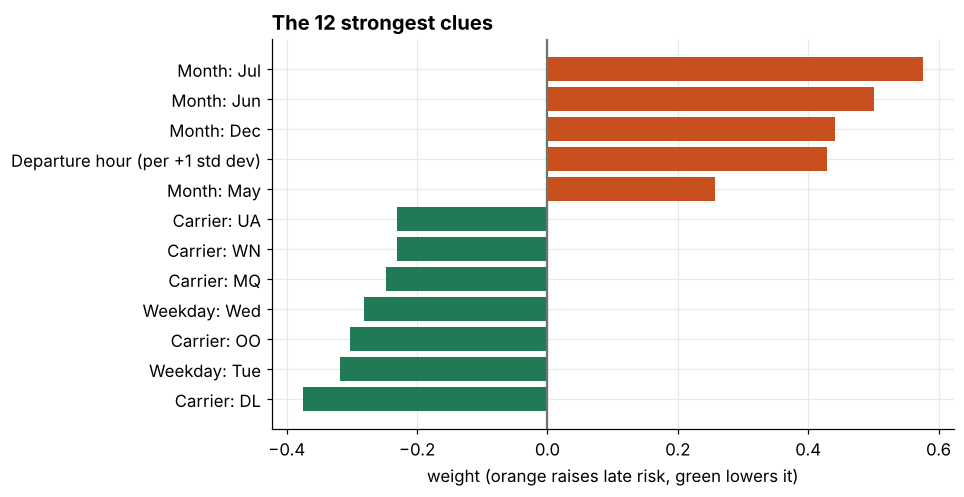

In [23]:
# model weights, in plain names. Reference categories are the first one of each clue (Jan, carrier AA, Monday...).
names = model[0].get_feature_names_out()
weights = pd.Series(model[-1].coef_[0], index=names)
DAYS = {'1': 'Mon', '2': 'Tue', '3': 'Wed', '4': 'Thu', '5': 'Fri', '6': 'Sat', '7': 'Sun'}
def pretty(n):
    if n == 'num__hour': return 'Departure hour (per +1 std dev)'
    if n == 'num__DISTANCE': return 'Distance (per +1 std dev)'
    kind, val = n.split('__')[1].rsplit('_', 1)
    if kind == 'MONTH': return f'Month: {MONTHS[int(float(val)) - 1]}'
    if kind == 'DAY_OF_WEEK': return f'Weekday: {DAYS[str(int(float(val)))]}'
    return f'Carrier: {val}'
weights.index = [pretty(n) for n in weights.index]
top = weights.reindex(weights.abs().sort_values(ascending=False).head(12).index).sort_values()
R['top_weights'] = top.round(3).to_dict()

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(top.index, top.values, color=[ORANGE if v > 0 else GREEN for v in top.values])
ax.axvline(0, color=GRAY); ax.set_xlabel('weight (orange raises late risk, green lowers it)'); ax.set_title('The 12 strongest clues'); plt.show()

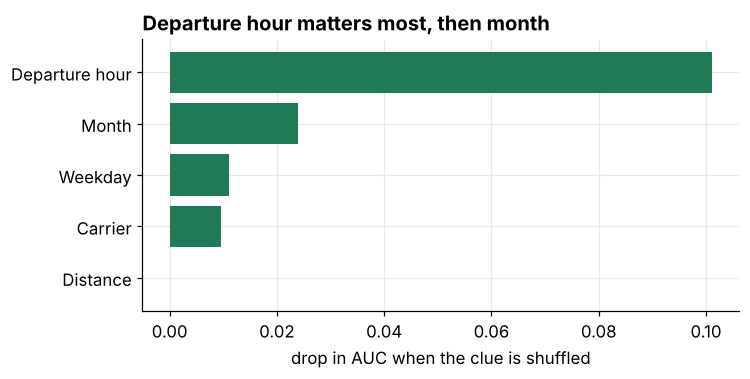

In [24]:
from sklearn.inspection import permutation_importance
test300 = test.sample(300_000, random_state=1)
perm = permutation_importance(model, test300[FEATURES], test300['late'].astype(int), scoring='roc_auc', n_repeats=3, random_state=0)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
R['perm_importance'] = imp.round(4).to_dict()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(['Distance' if f == 'DISTANCE' else {'hour': 'Departure hour', 'MONTH': 'Month', 'DAY_OF_WEEK': 'Weekday', 'OP_CARRIER': 'Carrier'}[f] for f in imp.index], imp.values, color=GREEN)
ax.set_xlabel('drop in AUC when the clue is shuffled'); ax.set_title('Departure hour matters most, then month'); plt.show()

**Answer 10: departure hour first, month second.** Shuffling the hour drops AUC by 0.101, month by 0.024, weekday 0.011, carrier 0.009, distance about zero. In the weights, July, June and December push risk up most; Delta, United, Southwest and Tuesday/Wednesday pull it down.

## 11. What if we change the hour or the month?

> **Question 11: If every flight left at one given hour (or month), what chance of late would the model predict?**

This is the **what-if** test: change one clue for every flight, leave the others as they are, and average the predicted risk. It isolates the effect of that clue. We overlay the **actual** late rate to check the model is honest. Both are **associations, not causes**.

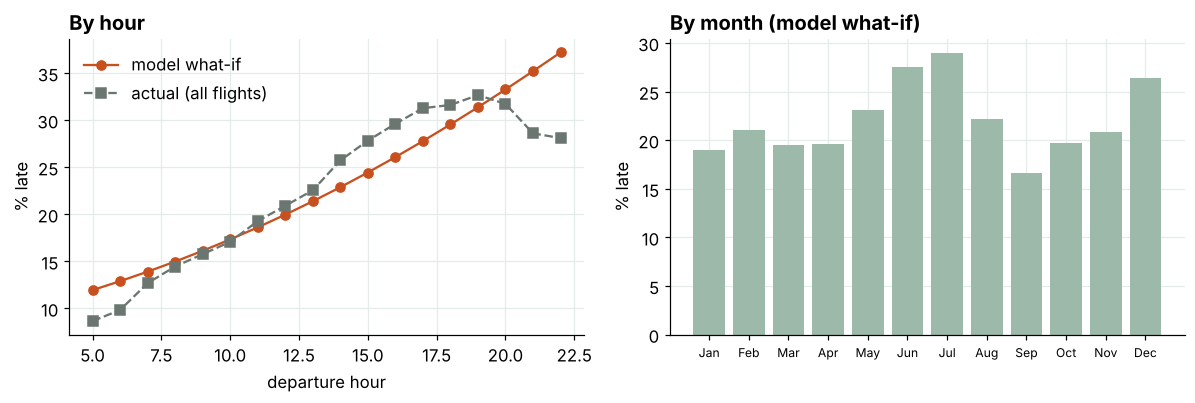

6 am -> 7 pm: 12.9% -> 31.4%    |    Sep -> Jul: 16.6% -> 29.0%


In [25]:
# SLIDE 9: predicted chance of late by departure hour (what-if) vs the actual rate
Xw = test500[FEATURES].copy()
what_hour = pd.Series({h: model.predict_proba(Xw.assign(hour=h))[:, 1].mean() * 100 for h in range(5, 23)})
R['whatif_6am'], R['whatif_7pm'] = what_hour[6], what_hour[19]
what_month = pd.Series({m: model.predict_proba(Xw.assign(MONTH=m))[:, 1].mean() * 100 for m in range(1, 13)})
R['whatif_sep'], R['whatif_jul'] = what_month[9], what_month[7]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(what_hour.index, what_hour.values, 'o-', color=ORANGE, label='model what-if')
axes[0].plot(late_by_hour.loc[5:22].index, late_by_hour.loc[5:22].values, 's--', color=GRAY, label='actual (all flights)')
axes[0].set_xlabel('departure hour'); axes[0].set_ylabel('% late'); axes[0].set_title('By hour'); axes[0].legend(frameon=False)
axes[1].bar(range(12), what_month.values, color=LIGHT); axes[1].set_xticks(range(12)); axes[1].set_xticklabels(MONTHS, fontsize=8)
axes[1].set_title('By month (model what-if)'); axes[1].set_ylabel('% late')
plt.tight_layout(); plt.show()
print(f"6 am -> 7 pm: {R['whatif_6am']:.1f}% -> {R['whatif_7pm']:.1f}%    |    Sep -> Jul: {R['whatif_sep']:.1f}% -> {R['whatif_jul']:.1f}%")

**Answer 11: later and summer both raise the risk.** Moving every flight from 6 am to 7 pm lifts predicted late from **12.9%** to **31.4%**, close to the actual rates. Moving from September to July lifts it from 16.6% to 29.0%. These are associations, not proof the hour or month causes the delay.

## 12. Where should the cutoff be?

> **Question 12: At what risk level should we act on a flight?**

The default 50% cutoff almost never fires. A better cutoff comes from **costs**:

* **Miss**: we did nothing and the flight was late. Cost = hours late x `VALUE_OF_TIME`.
* **Action**: we flagged the flight and spent a little time (an earlier flight, a buffer). Cost = `ACTION_MIN` minutes. We assume acting avoids the delay.

Flag a flight when **chance of late x miss cost > action cost**, so the best cutoff is **action cost / miss cost** (the break-even risk). We score every cutoff on the unseen test flights.

In [26]:
# cost per flight at each cutoff, on the unseen test flights
y = y_test.values
def cost_at(t):
    flag = p_test >= t
    tp, fp = (flag & (y == 1)).sum(), (flag & (y == 0)).sum()
    fn = ((~flag) & (y == 1)).sum()
    return (fn * R['miss_cost'] + (tp + fp) * R['action_cost']) / len(y), int(flag.sum()), tp / y.sum(), tp / max(flag.sum(), 1)

do_nothing = y.mean() * R['miss_cost']                                       # every late flight is a miss
R['do_nothing'] = do_nothing
rows = []
for t in [0.5, 0.4, 0.3, R['break_even'], 0.2, 0.15, 0.1]:
    c, flagged, recall, prec = cost_at(t)
    rows.append({'cutoff': round(t, 2), 'flights flagged (%)': round(flagged / len(y) * 100, 1), 'late flights caught (%)': round(recall * 100, 1),
                 'cost per flight ($)': round(c, 2), 'saving per 1,000 flights ($)': round((do_nothing - c) * 1000)})
cutoff_table = pd.DataFrame(rows)
R['cutoff_table'] = rows
print(f"Doing nothing costs ${do_nothing:.2f} per flight. Break-even rule says flag above {R['break_even']:.2f}.")
cutoff_table

Doing nothing costs $13.73 per flight. Break-even rule says flag above 0.24.


,cutoff,flights flagged (%),late flights caught (%),cost per flight ($),"saving per 1,000 flights ($)"
0,0.50,0.3,0.7,13.68,46
1,0.40,4.1,7.7,13.29,445
2,0.30,19.3,31.2,12.34,1394
3,0.24,36.3,52.4,11.97,1760
4,0.20,52.6,69.1,12.14,1588
5,0.15,75.6,86.9,13.14,593
6,0.10,96.1,98.4,14.63,-899


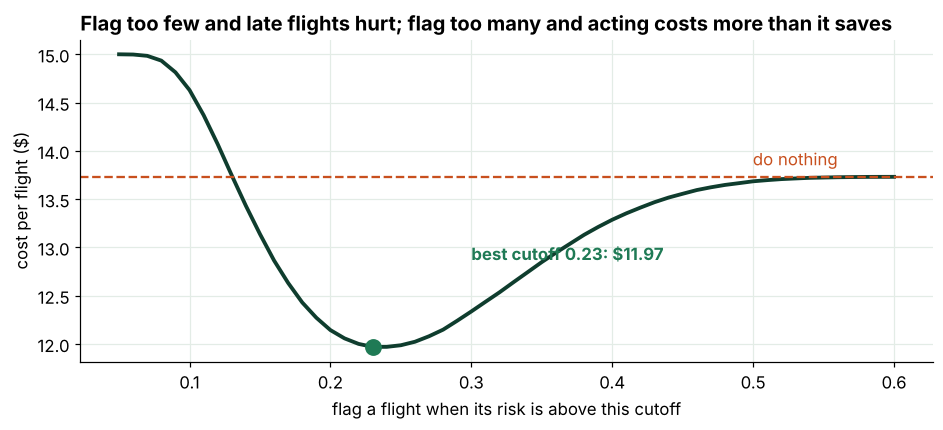

Lowest-cost cutoff on the curve: 0.23 ($11.97 per flight). The break-even rule (0.24) is within pennies of it.
Break-even rule: $11.97 per flight vs $13.73 doing nothing -> saves $1.76 per flight, $1,760 per 1,000 flights, $3,520 a year at 2,000 flights
At the rule: flag 36% of flights, catch 52% of late flights, 32% of flags are really late


In [27]:
# SLIDE 8 (supporting): cost per flight across all cutoffs, the minimum is the best cutoff
grid_t = np.arange(0.05, 0.61, 0.01)
curve = np.array([cost_at(t)[0] for t in grid_t])
best_t = grid_t[curve.argmin()]
R['best_cutoff'], R['best_cost'] = float(best_t), float(curve.min())
c25, flagged25, recall25, prec25 = cost_at(R['break_even'])      # the break-even rule (about 0.24) is the cutoff we recommend
R['saving_per_flight'] = do_nothing - c25
R['saving_per_1000'] = R['saving_per_flight'] * 1000
R['saving_per_year'] = R['saving_per_flight'] * PROGRAM_FLIGHTS
R['best_saving_per_1000'] = (do_nothing - curve.min()) * 1000
R['flagged25_pct'], R['caught25_pct'], R['precision25_pct'], R['cost25'] = flagged25 / len(y) * 100, recall25 * 100, prec25 * 100, c25

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(grid_t, curve, color=NAVY, lw=2.5); ax.axhline(do_nothing, color=ORANGE, ls='--'); ax.text(0.56, do_nothing + 0.12, 'do nothing', color=ORANGE, ha='right')
ax.plot(best_t, curve.min(), 'o', color=GREEN, ms=10); ax.annotate(f'best cutoff {best_t:.2f}: ${curve.min():.2f}', (best_t, curve.min()), (best_t + 0.07, curve.min() + 0.9), color=GREEN, fontweight='bold')
ax.set_xlabel('flag a flight when its risk is above this cutoff'); ax.set_ylabel('cost per flight ($)')
ax.set_title('Flag too few and late flights hurt; flag too many and acting costs more than it saves'); plt.show()
print(f"Lowest-cost cutoff on the curve: {best_t:.2f} (${curve.min():.2f} per flight). The break-even rule ({R['break_even']:.2f}) is within pennies of it.")
print(f"Break-even rule: ${c25:.2f} per flight vs ${do_nothing:.2f} doing nothing -> saves ${R['saving_per_flight']:.2f} per flight, ${R['saving_per_1000']:,.0f} per 1,000 flights, ${R['saving_per_year']:,.0f} a year at {PROGRAM_FLIGHTS:,} flights")
print(f"At the rule: flag {R['flagged25_pct']:.0f}% of flights, catch {R['caught25_pct']:.0f}% of late flights, {R['precision25_pct']:.0f}% of flags are really late")

**Answer 12: flag flights above about 0.24.** Doing nothing costs $13.73 per flight. At the break-even rule we flag 36% of flights, catch 52% of late flights, and cost $11.97: a saving of **$1,760 per 1,000 flights** ($3,520 a year at 2,000 flights). The lowest point on the curve (0.23) is within a few dollars per 1,000 of the rule. Flagging too much (cutoff 0.10) loses money.

## 13. Does a risk badge work?

> **Question 13: If we label each flight Low, Medium or High risk at checkout, do the labels mean something?**

Tiers use the break-even line: **Low** under 15%, **Medium** 15% to the break-even risk, **High** at or above it. We check the **actual** late rate in each tier on the unseen flights. A label is only useful if High is really worse than Low.

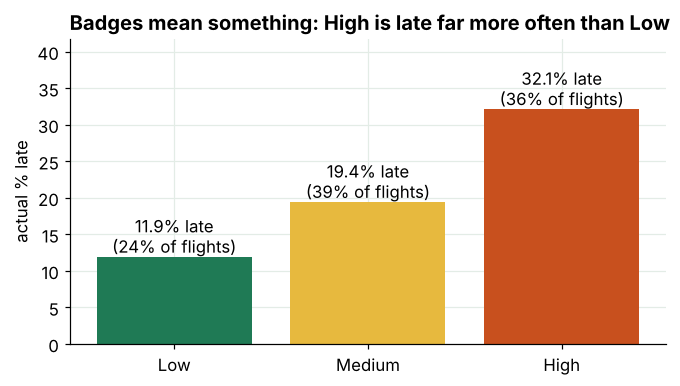

,flights,late_rate,share of flights %
tier,,,
Low,1484528,11.9,24.4
Medium,2395256,19.4,39.3
High,2208567,32.1,36.3


In [28]:
# SLIDE 7: badge tiers and how often flights in each tier are really late
tier = pd.cut(p_test, [0, 0.15, R['break_even'], 1], labels=['Low', 'Medium', 'High'], right=False)
tiers = pd.DataFrame({'tier': tier, 'late': y}).groupby('tier').agg(flights=('late', 'size'), late_rate=('late', 'mean'))
tiers['share of flights %'] = (tiers['flights'] / len(y) * 100).round(1); tiers['late_rate'] = (tiers['late_rate'] * 100).round(1)
R['tiers'] = tiers.reset_index().to_dict('records')

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(tiers.index.astype(str), tiers['late_rate'], color=[GREEN, '#E7B93E', ORANGE])
for i, (r, s) in enumerate(zip(tiers['late_rate'], tiers['share of flights %'])): ax.text(i, r + 0.6, f'{r:.1f}% late\n({s:.0f}% of flights)', ha='center')
ax.set_ylabel('actual % late'); ax.set_ylim(0, tiers['late_rate'].max() * 1.3); ax.set_title('Badges mean something: High is late far more often than Low'); plt.show()
tiers

**Answer 13: yes.** On unseen flights, Low badges are late **11.9%** of the time, Medium **19.4%**, High **32.1%** (about 2.7x). The labels carry real information.

## 14. Book before 10 am

> **Question 14: What does a "book time-critical trips before 10 am" rule save?**

Straight from all flights: compare the late rate and the expected delay cost for flights departing **before 10 am** with flights departing **5 pm or later**. This is an **association** (routes and aircraft rotation differ by hour), so treat it as the typical gain.

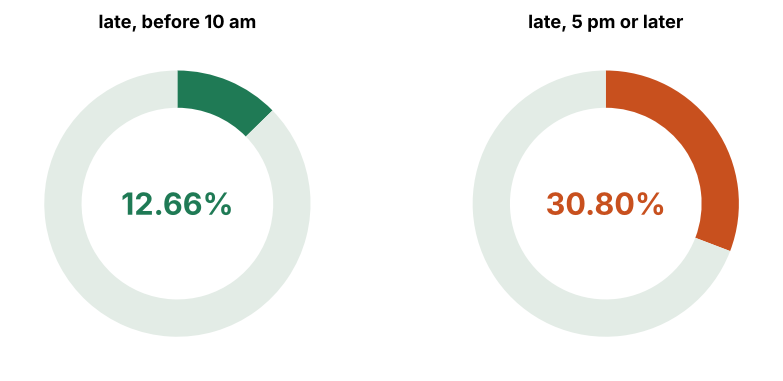

Moving 1,000 trips from 5 pm+ to before 10 am avoids about 181 late arrivals (+/- 0.8) and saves $12.53 per trip ($20.80 -> $8.27)


In [29]:
# SLIDE 6: two donuts (late rate before 10 am vs from 5 pm) and the savings per trip moved
diff = R['late_after17'] - R['late_before10']
R['avoided_per_1000'] = diff * 10                                              # percentage points x 10 = per 1,000 trips
R['saved_per_trip'] = R['cost_after17'] - R['cost_before10']
se = np.sqrt((R['late_after17'] / 100) ** 2 * 0 + R['late_after17'] / 100 * (1 - R['late_after17'] / 100) / R['n_after17'] + R['late_before10'] / 100 * (1 - R['late_before10'] / 100) / R['n_before10'])
R['avoided_ci'] = 1.96 * se * 1000

fig, axes = plt.subplots(1, 2, figsize=(8, 3.6))
donut(axes[0], R['late_before10'], 'late, before 10 am', GREEN); donut(axes[1], R['late_after17'], 'late, 5 pm or later', ORANGE)
plt.tight_layout(); plt.show()
print(f"Moving 1,000 trips from 5 pm+ to before 10 am avoids about {R['avoided_per_1000']:.0f} late arrivals (+/- {R['avoided_ci']:.1f}) and saves ${R['saved_per_trip']:.2f} per trip (${R['cost_after17']:.2f} -> ${R['cost_before10']:.2f})")

**Answer 14: about 181 fewer late arrivals per 1,000 trips**, and $12.53 less expected delay cost per trip ($20.80 to $8.27). Treat it as the typical gain: route mix differs by hour.

## 15. The business case

> **Question 15: For a travel program of `PROGRAM_FLIGHTS` flights a year, what is at stake and what can the moves recover?**

The program size and the value of time are **assumptions**, so the dollars scale with them. Change them at the top and re-run.

At stake: delay cost per year                                                       34114.0
Protect flights above break-even: saving per year                                    3520.0
Every flight 5 pm+ moved to before 10 am: saving per year if 10% of flights move     2506.0


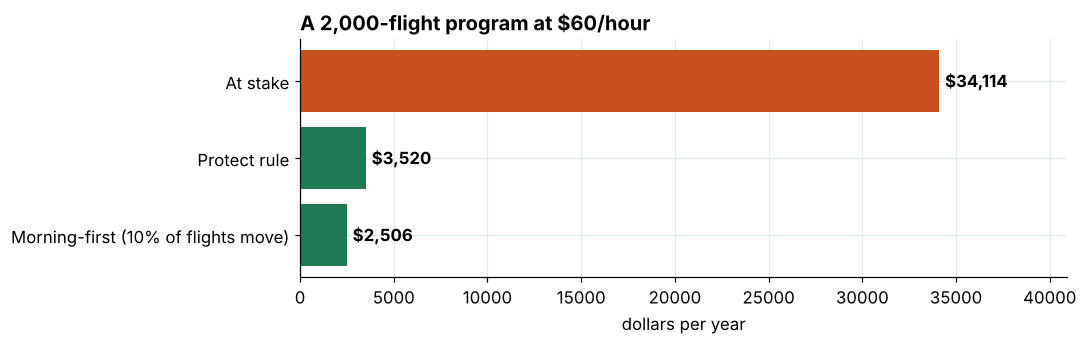

Value of time $30 to $150 an hour moves the yearly cost from $17,057 to $85,284


In [30]:
# SLIDE 10: yearly dollars for the program
R['stake_year'] = R['trip_cost'] * PROGRAM_FLIGHTS
R['range_year'] = [round(r[f'per year, {PROGRAM_FLIGHTS:,} flights ($)']) for r in (R['vot_table'][0], R['vot_table'][-1])]
levers = pd.Series({'At stake: delay cost per year': R['stake_year'],
                    'Protect flights above break-even: saving per year': R['saving_per_year'],
                    'Every flight 5 pm+ moved to before 10 am: saving per year if 10% of flights move': R['saved_per_trip'] * PROGRAM_FLIGHTS * 0.10})
print(levers.round(0).to_string())

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(['Morning-first (10% of flights move)', 'Protect rule', 'At stake'][::-1][::-1], [levers.iloc[2], levers.iloc[1], levers.iloc[0]], color=[GREEN, GREEN, ORANGE])
for i, v in enumerate([levers.iloc[2], levers.iloc[1], levers.iloc[0]]): ax.text(v + 300, i, f'${v:,.0f}', va='center', fontweight='bold')
ax.set_xlim(0, levers.iloc[0] * 1.2); ax.set_xlabel('dollars per year'); ax.set_title(f'A {PROGRAM_FLIGHTS:,}-flight program at ${VALUE_OF_TIME}/hour'); plt.show()
print(f"Value of time $30 to $150 an hour moves the yearly cost from ${R['range_year'][0]:,} to ${R['range_year'][1]:,}")

**Answer 15: about $34,114 a year is at stake** for a 2,000-flight program at $60/hour ($17,057 to $85,284 across $30 to $150). The protect rule recovers about $3,520; moving 10% of flights to mornings recovers about $2,506. The bigger prize is steering the high-risk months and hours, since the cost sits in them.

**Answer 15: about $34,114 a year is at stake** for a 2,000-flight program at $60/hour ($17,057 to $85,284 across $30 to $150). The protect rule recovers about $3,520; moving 10% of flights to mornings recovers about $2,506. The bigger prize is steering the high-risk months and hours, since the cost sits in them.

## 16. Every number in the slides

One table, so anything in the deck can be traced back to a cell. Statistics come from **all flights**; model results come from **training on the sample and testing on unseen flights**.

In [31]:
summary = pd.DataFrame([
    ('2', 'Flights disrupted', f"{R['disrupted_pct']:.2f}%", 'all flights'),
    ('2', 'Flights cancelled', f"{R['cancelled_pct']:.2f}%", 'all flights'),
    ('2', 'Late, of flights that flew', f"{R['late_pct']:.2f}%", 'all flights'),
    ('2', 'Late at 6 am / 7 pm', f"{R['late_6am']:.1f}% / {R['late_7pm']:.1f}%", 'all flights'),
    ('2, 6', 'Late before 10 am / from 5 pm', f"{R['late_before10']:.1f}% / {R['late_after17']:.1f}%", 'all flights'),
    ('3', 'Arrive within 60 minutes', f"{R['within60_pct']:.1f}%", 'all flights'),
    ('3', 'Late flights under an hour late', f"{R['late_under60_of_late']:.1f}%", 'all flights'),
    ('5', 'Expected delay cost per flight', f"${R['trip_cost']:.2f} ({R['trip_cost_pct_fare']:.1f}% of fare)", 'all flights + assumptions'),
    ('5', 'Cost 6-9 am / 5-8 pm', f"${R['cost_6_9']:.2f} / ${R['cost_17_20']:.2f}", 'all flights + assumptions'),
    ('4', 'Accuracy: always on time / our model', f"{R['baseline_accuracy']:.1f}% / {R['model_accuracy']:.1f}%", 'test: unseen flights'),
    ('4', 'Late flights caught at 50% cutoff', f"{R['recall50']:.2f}% ({R['caught50']:,} of {R['late_total']:,})", 'test: unseen flights'),
    ('7', 'Late rate: lowest / highest risk group', f"{R['decile_actual'][0]:.1f}% / {R['decile_actual'][-1]:.1f}%", 'test: unseen flights'),
    ('7', 'Badge tiers late rate (Low / Medium / High)', ' / '.join(f"{t['late_rate']:.1f}%" for t in R['tiers']), 'test: unseen flights'),
    ('8', 'Break-even risk', f"{R['break_even']:.2f}", 'assumptions + all flights'),
    ('8', 'Break-even rule: saving per 1,000 flights', f"${R['saving_per_1000']:,.0f} (lowest-cost cutoff {R['best_cutoff']:.2f})", 'test: unseen flights'),
    ('8', 'Flights flagged / late caught at the rule', f"{R['flagged25_pct']:.0f}% / {R['caught25_pct']:.0f}%", 'test: unseen flights'),
    ('6', 'Late arrivals avoided per 1,000 trips moved', f"{R['avoided_per_1000']:.0f}", 'all flights'),
    ('6', 'Saving per trip moved', f"${R['saved_per_trip']:.2f}", 'all flights + assumptions'),
    ('9', 'Disrupted: September / July', f"{R['dis_by_month'][9]:.1f}% / {R['dis_by_month'][7]:.1f}%", 'all flights'),
    ('9', 'Model what-if: 6 am / 7 pm', f"{R['whatif_6am']:.1f}% / {R['whatif_7pm']:.1f}%", 'sample-trained model'),
    ('10', 'Delay cost at stake per year', f"${R['stake_year']:,.0f}", 'all flights + assumptions'),
    ('10', 'Protect rule saving per year', f"${R['saving_per_year']:,.0f}", 'test + assumptions'),
    ('App.', 'AUC on unseen flights', f"{R['auc']:.3f}", 'test: unseen flights'),
], columns=['slide', 'number', 'value', 'source'])
summary

,slide,number,value,source
0,2,Flights disrupted,23.55%,all flights
1,2,Flights cancelled,1.49%,all flights
2,2,"Late, of flights that flew",22.17%,all flights
3,2,Late at 6 am / 7 pm,9.8% / 32.7%,all flights
4,"2, 6",Late before 10 am / from 5 pm,12.7% / 30.8%,all flights
5,3,Arrive within 60 minutes,91.9%,all flights
6,3,Late flights under an hour late,63.6%,all flights
7,5,Expected delay cost per flight,$17.06 (7.2% of fare),all flights + assumptions
8,5,Cost 6-9 am / 5-8 pm,$8.43 / $21.75,all flights + assumptions
9,4,Accuracy: always on time / our model,77.8% / 77.8%,test: unseen flights


In [32]:
# a machine-readable copy of every result (used to build the slides)
print('RESULTS_JSON=' + json.dumps(R, default=lambda o: float(o) if hasattr(o, '__float__') else str(o)))

RESULTS_JSON={"n_full": 6398056, "n_sample": 200000, "disrupted_pct": 23.546964890585514, "cancelled_pct": 1.4874205539932754, "late_pct": 22.170166020830333, "disrupted_n": 1506548, "n_flew": 6284874, "late_6am": 9.826512330334781, "late_7pm": 32.65726060662666, "late_before10": 12.662976243789165, "late_after17": 30.803616612125097, "n_before10": 1880182, "n_after17": 1778460, "ratio_evening_morning": 2.4325731975714167, "late_worst_cell": 46.432972306894094, "hot_late": 44.60223931741777, "hot_n": 246593, "calm_late": 8.794720298417916, "calm_n": 153342, "hot_ratio": 5.071479001491529, "sev_shares": [77.83, 14.09, 4.77, 1.72, 1.59], "within60_pct": 91.92219287132885, "late_under60_of_late": 63.56451674253803, "dis_by_month": {"1": 21.25, "2": 22.01, "3": 20.53, "4": 20.41, "5": 24.53, "6": 29.58, "7": 31.04, "8": 23.57, "9": 17.22, "10": 20.83, "11": 22.58, "12": 27.64}, "late_hours": 1.0321609214705578, "late_cost": 13.487024496190719, "cancel_cost": 3.569809329583861, "trip_cost":

## Caveats and glossary

**Read this before presenting.**

* **Association, not cause.** Evenings are late more often, but we have not shown that the hour itself causes delays (route mix and aircraft rotation also differ by hour).
* **Dollars rest on assumptions.** `VALUE_OF_TIME`, `CANCEL_HOURS`, `ACTION_MIN` and `PROGRAM_FLIGHTS` are not in any dataset. Change them and the dollars move; the ranking of ideas does not.
* **The action assumption.** We assume acting on a flagged flight (earlier flight, buffer) fully avoids the delay. Real savings could be lower.
* **Modest model.** The risk score uses only five clues. It ranks flights well enough to act on, but it cannot say *which* single flight will be late.
* **Delay is capped at 180 minutes** when computing cost, so very long delays do not dominate the averages.

| Term | Plain meaning |
|---|---|
| Late | Arrived 15+ minutes after schedule |
| Disrupted | Cancelled, diverted, or late |
| Accuracy | Share of flights the model called right (misleading when one outcome dominates) |
| Cutoff | The risk level above which we act on a flight |
| Break-even risk | Action cost / miss cost: above it, acting is cheaper than waiting |
| AUC | Chance a late flight scores higher than an on-time flight (0.5 = coin flip, 1 = perfect) |
| Overfitting | Memorizing the training data and doing worse on new flights |
| What-if | Change one clue for every flight and see how the prediction moves |